# CR02 - Monotone LightGBM challenger vs WOE scorecard (LendingClub)

Out-of-time validation. Train on loans issued 2007 to 2014, test on loans issued 2015 to 2016.
Target: 1 = fully paid, 0 = charged off or default. Only resolved statuses are used.
Compare a WOE logistic scorecard with a LightGBM model whose monotone constraints follow credit logic.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_core.datasets import LC_CATEGORICAL, LC_MONOTONE, LC_NUMERIC
from credit_core.metrics import discrimination, expected_calibration_error
from credit_core.plots import plot_monthly_metric, plot_reliability, plot_roc
from gbm_monotone.checks import partial_dependence, violates_monotone
from gbm_monotone.pipeline import challenger_scores, fit_challenger, fit_woe_scorecard, load_oot

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Load, split, and summarise by vintage

In [2]:
d = load_oot()
print("train", len(d.y_train), "test", len(d.y_test))
print("good rate train", round(d.y_train.mean(), 3), "test", round(d.y_test.mean(), 3))

train 453809 test 668651
good rate train 0.83 test 0.785


## 2. Fit the baseline scorecard and the challenger

In [3]:
sc, C = fit_woe_scorecard(d)
print("WOE scorecard C:", C)
gbm = fit_challenger(d)

X_te = d.X_test
p_woe = sc.predict_good(X_te[LC_NUMERIC + LC_CATEGORICAL])
p_gbm = challenger_scores(gbm, d, X_te)

WOE scorecard C: 0.1


## 3. Discrimination on the out-of-time test set

,auc,gini,ks,ECE
model,,,,
WOE scorecard,0.6899,0.3798,0.2695,0.0476
LightGBM monotone,0.7149,0.4297,0.3090,0.0440


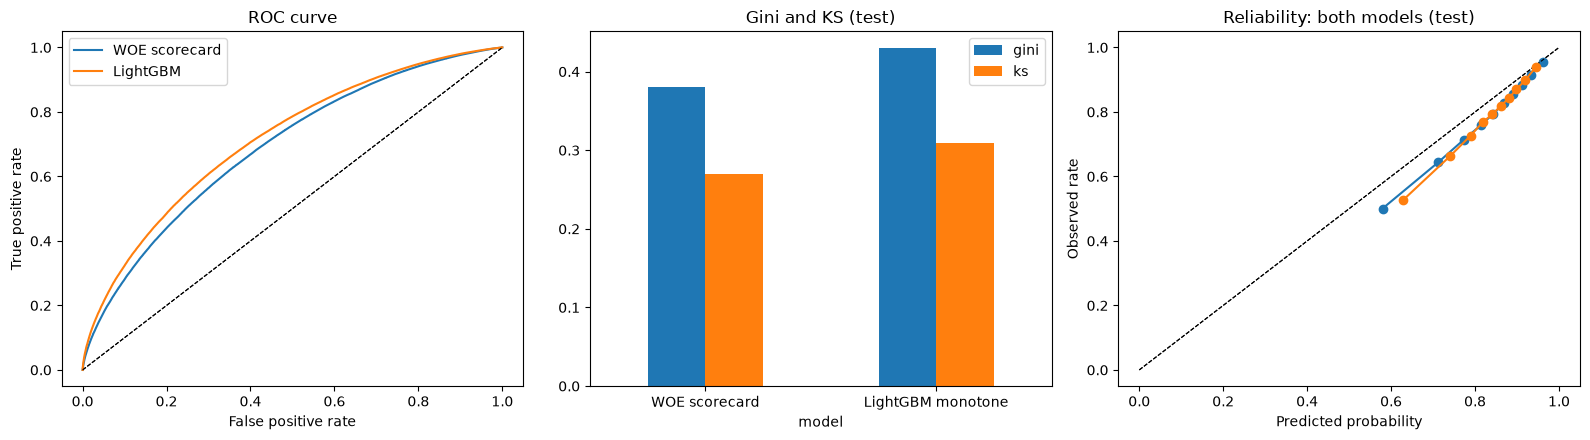

In [4]:
rows = []
for name, p in [("WOE scorecard", p_woe), ("LightGBM monotone", p_gbm)]:
    m = discrimination(d.y_test, p)
    rows.append({"model": name, **m, "ECE": expected_calibration_error(d.y_test, p)})
res = pd.DataFrame(rows).set_index("model")
display(res.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_roc(d.y_test, p_woe, label="WOE scorecard", ax=axes[0])
plot_roc(d.y_test, p_gbm, label="LightGBM", ax=axes[0])
res[["gini", "ks"]].plot.bar(ax=axes[1], rot=0, title="Gini and KS (test)")
plot_reliability(d.y_test, p_gbm, ax=axes[2])
plot_reliability(d.y_test, p_woe, ax=axes[2])
axes[2].set_title("Reliability: both models (test)")
fig.tight_layout()
fig.savefig(FIG / "cr02_discrimination.png", dpi=120)
plt.show()

## 4. Stability over time (quarterly Gini on the test window)

,period,n,gini_woe,gini_gbm
0,2015Q1,76803,0.397,0.437
1,2015Q2,85942,0.398,0.442
2,2015Q3,97904,0.427,0.466
3,2015Q4,114897,0.410,0.455
4,2016Q1,111934,0.402,0.453
5,2016Q2,62949,0.343,0.402
6,2016Q3,60891,0.324,0.381
7,2016Q4,57331,0.314,0.369


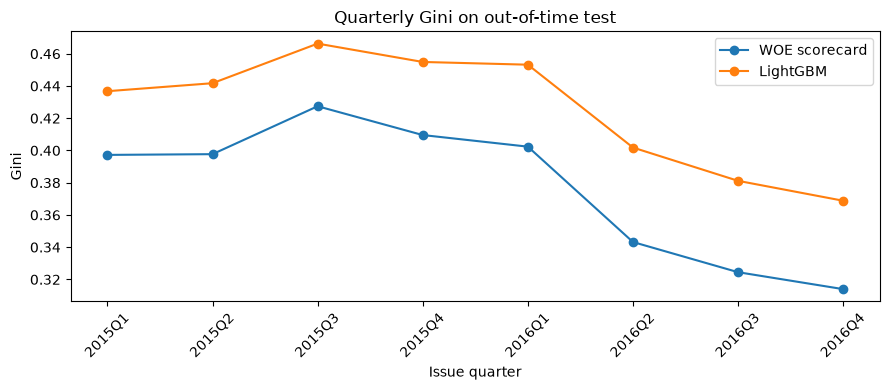

In [5]:
q = d.issue_test.dt.to_period("Q").astype(str)
quarterly = []
for period in sorted(q.unique()):
    mask = (q == period).to_numpy()
    quarterly.append(
        {
            "period": period,
            "n": int(mask.sum()),
            "gini_woe": discrimination(d.y_test[mask], p_woe[mask])["gini"],
            "gini_gbm": discrimination(d.y_test[mask], p_gbm[mask])["gini"],
        }
    )
quarterly = pd.DataFrame(quarterly)
display(quarterly.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(quarterly["period"], quarterly["gini_woe"], marker="o", label="WOE scorecard")
ax.plot(quarterly["period"], quarterly["gini_gbm"], marker="o", label="LightGBM")
ax.set(title="Quarterly Gini on out-of-time test", ylabel="Gini", xlabel="Issue quarter")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "cr02_quarterly_gini.png", dpi=120)
plt.show()

## 5. Monotonicity check of the challenger

`LC_MONOTONE` gives the direction of default risk. The model predicts good (1), so the
expected direction of good probability is the opposite sign. Each curve is averaged over 500 test rows.

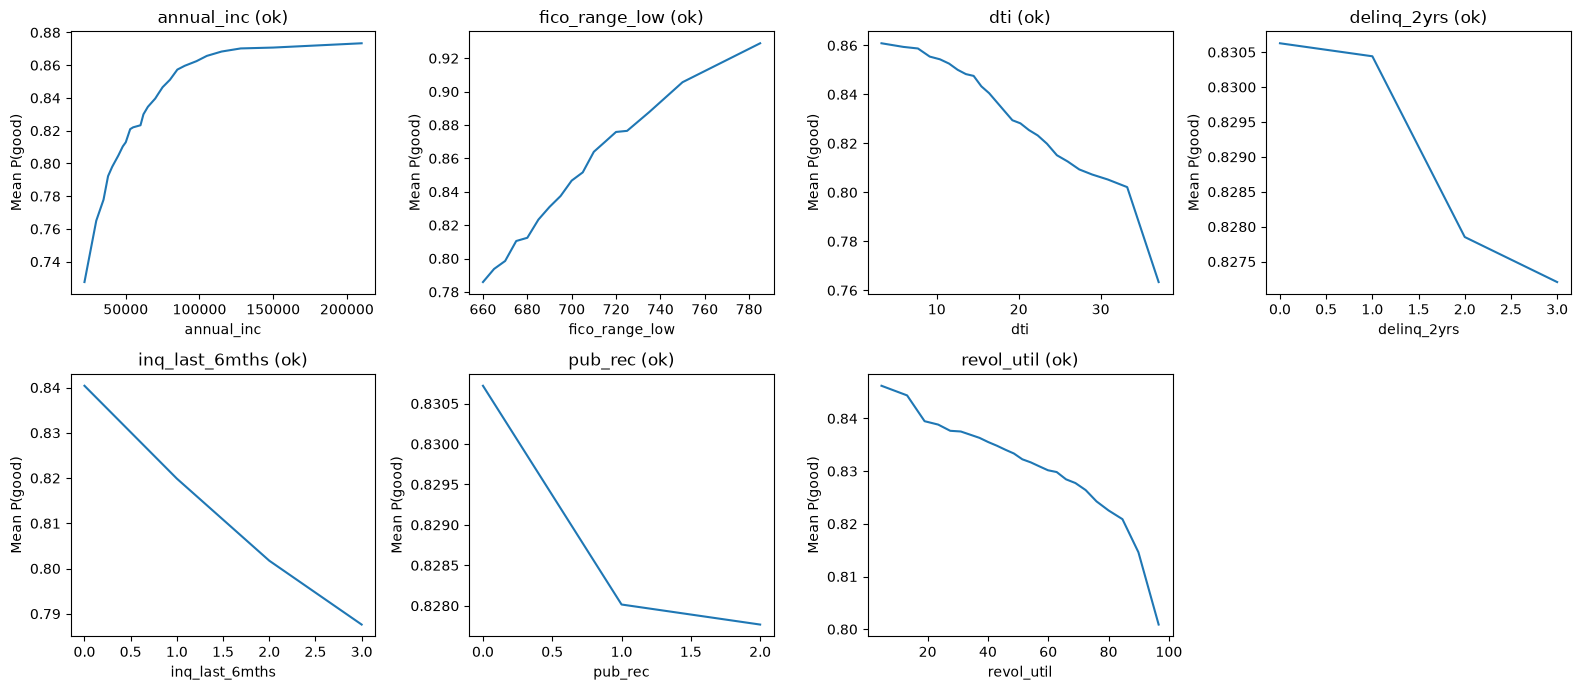

,feature,good_direction,monotone
0,annual_inc,1,True
1,fico_range_low,1,True
2,dti,-1,True
3,delinq_2yrs,-1,True
4,inq_last_6mths,-1,True
5,pub_rec,-1,True
6,revol_util,-1,True


In [6]:
checks = []
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (feature, risk_dir) in zip(axes.ravel(), LC_MONOTONE.items()):
    grid = np.quantile(d.X_test[feature].dropna(), np.linspace(0.02, 0.98, 25))
    curve = partial_dependence(lambda X: challenger_scores(gbm, d, X), d.X_test, feature, grid)
    good_dir = -risk_dir
    ok = not violates_monotone(curve, good_dir)
    checks.append({"feature": feature, "good_direction": good_dir, "monotone": ok})
    ax.plot(grid, curve)
    ax.set(title=f"{feature} ({'ok' if ok else 'VIOLATION'})", xlabel=feature, ylabel="Mean P(good)")
for ax in axes.ravel()[len(LC_MONOTONE):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "cr02_partial_dependence.png", dpi=120)
plt.show()
display(pd.DataFrame(checks))

## 6. Feature importance (gain)

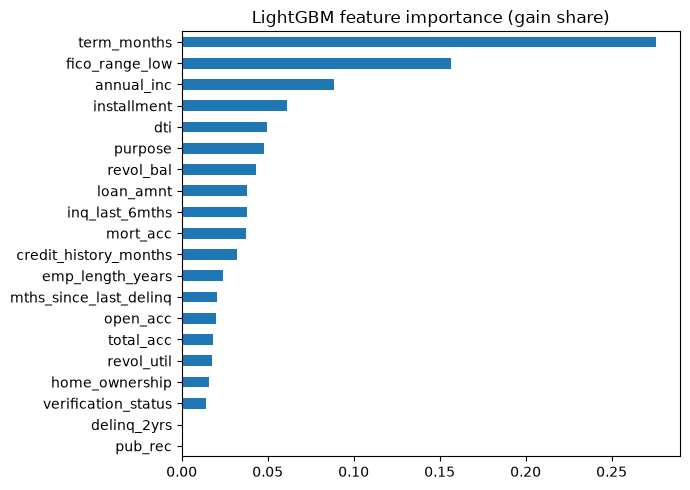

In [7]:
imp = pd.Series(gbm.booster_.feature_importance(importance_type="gain"), index=d.X_train.columns)
imp = imp.sort_values(ascending=True) / imp.sum()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, title="LightGBM feature importance (gain share)")
fig.tight_layout()
fig.savefig(FIG / "cr02_importance.png", dpi=120)
plt.show()

## 7. Summary

The challenger beats the WOE scorecard on the out-of-time test by the Gini gain above.
Constraints hold on the partial dependence checks. The gain is only worth it if it holds in later quarters.

In [8]:
gain = res.loc["LightGBM monotone", "gini"] - res.loc["WOE scorecard", "gini"]
print(f"Gini gain (LightGBM - WOE): {gain:+.4f}")

Gini gain (LightGBM - WOE): +0.0499
